# 04 — KPIs por região, UF e categoria de produto

**Objetivo:** localizar onde estão as maiores oportunidades: regiões/UFs do **cliente** e categorias de produto. Todos os cortes trazem o denominador e a flag `amostra_pequena` (denominador < 30), para não ranquear grupos minúsculos sem aviso. Nenhum grupo é removido.

- KPI1, KPI3 e % entrega atrasada vêm da tabela `pedidos` (1 linha/pedido).
- KPI2 vem da tabela `itens` (soma de frete / soma de preço).
- Por categoria, o pedido é contado em **cada categoria distinta que contém** (tabela `pedido_categoria`).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import olist_utils as U

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.max_rows", 120)
sns.set_theme(style="whitegrid")

pedidos = U.load_processed("pedidos")
itens = U.load_processed("itens")
pc = U.load_processed("pedido_categoria")

def kpis(by, base_ped=pedidos, base_it=itens):
    out = U.kpi_pedidos(base_ped, by).merge(U.kpi_frete(base_it, by), on=by, how="outer", validate="one_to_one")
    out = U.flag_amostra(out, "pedidos_com_avaliacao")
    return out

SHOW = ["pedidos_entregues", "pedidos_com_avaliacao", "kpi1_pct_avaliacao_ruim", "kpi2_pct_frete_sobre_produto",
        "kpi3_pct_postagem_no_prazo", "pct_entrega_atrasada", "amostra_pequena"]

## 1. Por região do cliente

In [2]:
reg = kpis(["ano_original", "periodo_comparativo", "regiao_cliente"])
reg["kpi2_referencia_proposta_2025"] = np.where(reg["ano_original"] == 2018,
                                                reg["regiao_cliente"].map(U.REF_FRETE_REGIAO_2025), np.nan)
reg["granularidade"] = "periodo_regiao_cliente"
reg.set_index(["periodo_comparativo", "regiao_cliente"])[SHOW + ["kpi2_referencia_proposta_2025"]].round(2)

pedidos_entregues  pedidos_com_avaliacao  kpi1_pct_avaliacao_ruim  kpi2_pct_frete_sobre_produto  kpi3_pct_postagem_no_prazo  \
periodo_comparativo       regiao_cliente                                                                                                                                
2024 (proxy jan-ago/2017) Centro-Oeste                 1208                   1202                    11.40                         15.36                       93.87   
                          Nordeste                     2210                   2193                    14.23                         20.45                       91.63   
                          Norte                         521                    519                    10.98                         20.63                       91.94   
                          Sudeste                     14633                  14512                    10.35                         14.77                       91.31   
                          Sul                          3426                   3411                     8.91                         17.11                       90.60   
2025 (proxy jan-ago/2018) Centro-Oeste                 3113                   3098                    13.40                         18.83                       92.03   
                          Nordeste                     4669                   4636                    17.45                         22.68                       91.20   
                          Norte                         866                    854                    17.56                         23.85                       92.96   
                          Sudeste                     36803                  36584                    12.96                         15.52                       91.26   
                          Sul                          7332                   7296                    12.36                         18.30                       92.13   

                                          pct_entrega_atrasada  amostra_pequena  kpi2_referencia_proposta_2025  
periodo_comparativo       regiao_cliente                                                                        
2024 (proxy jan-ago/2017) Centro-Oeste                    2.32            False                            NaN  
                          Nordeste                        7.69            False                            NaN  
                          Norte                           3.45            False                            NaN  
                          Sudeste                         3.02            False                            NaN  
                          Sul                             3.24            False                            NaN  
2025 (proxy jan-ago/2018) Centro-Oeste                    7.93            False                            NaN  
                          Nordeste                       14.44            False                           22.7  
                          Norte                          12.36            False                           23.9  
                          Sudeste                         6.95            False                           15.5  
                          Sul                             6.71            False                            NaN

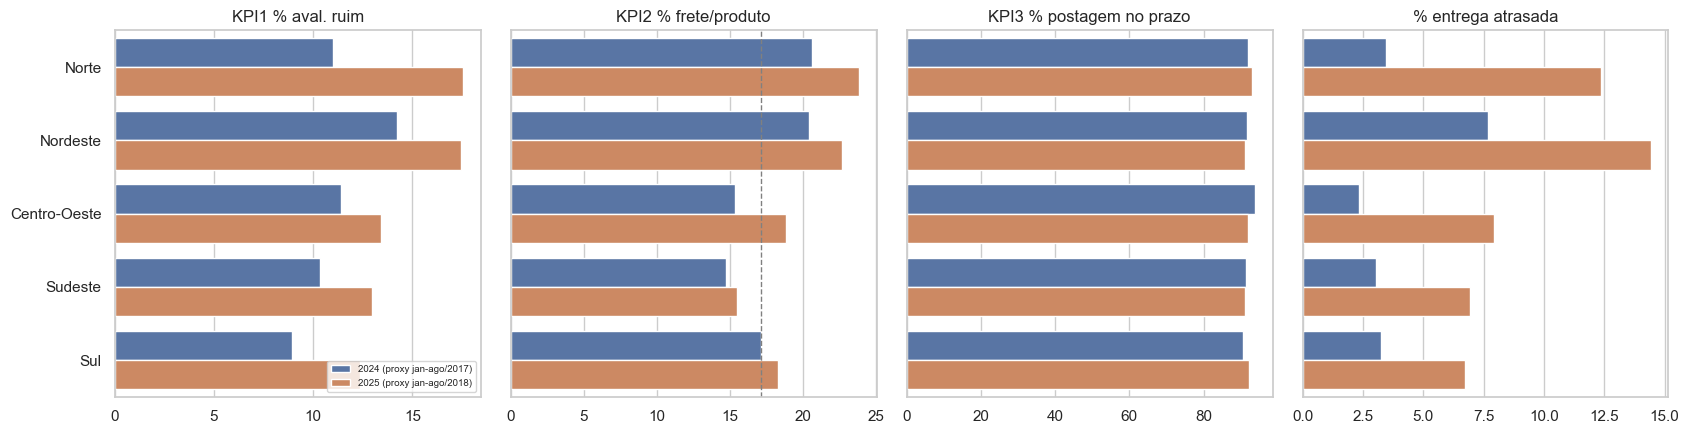

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5), sharey=True)
ordem = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
for ax, (col, t) in zip(axes, [("kpi1_pct_avaliacao_ruim", "KPI1 % aval. ruim"),
                              ("kpi2_pct_frete_sobre_produto", "KPI2 % frete/produto"),
                              ("kpi3_pct_postagem_no_prazo", "KPI3 % postagem no prazo"),
                              ("pct_entrega_atrasada", "% entrega atrasada")]):
    sns.barplot(data=reg, y="regiao_cliente", x=col, hue="periodo_comparativo", order=ordem, ax=ax)
    ax.set_title(t); ax.set_xlabel(""); ax.set_ylabel("")
    if ax is not axes[0]:
        ax.get_legend().remove()
axes[0].legend(fontsize=7, loc="lower right")
axes[1].axvline(17.1, ls="--", c="gray", lw=1)
fig.tight_layout(); fig.savefig(U.FIG_DIR / "04_kpis_regiao.png", dpi=120)

## 2. Por UF do cliente

In [4]:
uf = kpis(["ano_original", "periodo_comparativo", "customer_state"])
uf["regiao_cliente"] = uf["customer_state"].map(U.UF_REGIAO)
uf["granularidade"] = "periodo_uf_cliente"
uf25 = uf[uf["ano_original"] == 2018].sort_values("kpi1_pct_avaliacao_ruim", ascending=False)
uf25.set_index(["customer_state", "regiao_cliente"])[SHOW].round(2)

,,pedidos_entregues,pedidos_com_avaliacao,kpi1_pct_avaliacao_ruim,kpi2_pct_frete_sobre_produto,kpi3_pct_postagem_no_prazo,pct_entrega_atrasada,amostra_pequena
customer_state,regiao_cliente,,,,,,,
AL,Nordeste,198,197,21.32,21.88,87.37,22.22,False
PA,Norte,453,442,20.81,22.70,93.16,16.56,False
CE,Nordeste,633,629,20.35,22.83,92.42,19.12,False
MA,Nordeste,346,344,20.35,27.76,91.62,19.94,False
RJ,Sudeste,6342,6279,20.18,18.11,91.85,13.73,False
PI,Nordeste,258,256,19.92,24.93,91.86,16.67,False
RR,Norte,22,22,18.18,24.07,95.45,9.09,True
AM,Norte,72,72,18.06,25.89,93.06,4.17,False
SE,Nordeste,146,146,17.81,23.38,89.04,16.44,False


### Volume de oportunidade por UF (2025 proxy)
Uma taxa alta em UF pequena pesa pouco no KPI geral. Para priorizar, olhamos também o **excesso de pedidos ruins**: quantos pedidos ruins a UF tem acima do que teria se estivesse na taxa geral do período.

In [5]:
taxa_geral = uf25["pedidos_avaliacao_ruim"].sum() / uf25["pedidos_com_avaliacao"].sum()
uf25 = uf25.assign(excesso_pedidos_ruins=lambda d: d["pedidos_avaliacao_ruim"] - d["pedidos_com_avaliacao"] * taxa_geral)
uf25.sort_values("excesso_pedidos_ruins", ascending=False)[
    ["customer_state", "regiao_cliente", "pedidos_com_avaliacao", "kpi1_pct_avaliacao_ruim",
     "pct_entrega_atrasada", "kpi2_pct_frete_sobre_produto", "excesso_pedidos_ruins", "amostra_pequena"]].head(10).round(2)

,customer_state,regiao_cliente,pedidos_com_avaliacao,kpi1_pct_avaliacao_ruim,pct_entrega_atrasada,kpi2_pct_frete_sobre_produto,excesso_pedidos_ruins,amostra_pequena
45,RJ,Sudeste,6279,20.18,13.73,18.11,427.37,False
31,BA,Nordeste,1713,17.69,14.08,20.89,73.94,False
32,CE,Nordeste,629,20.35,19.12,22.83,43.89,False
40,PA,Norte,442,20.81,16.56,22.70,32.90,False
36,MA,Nordeste,344,20.35,19.94,27.76,24.00,False
34,ES,Sudeste,1035,15.07,13.75,17.67,17.60,False
43,PI,Nordeste,256,19.92,16.67,24.93,16.77,False
28,AL,Nordeste,197,21.32,22.22,21.88,15.66,False
42,PE,Nordeste,844,14.45,9.98,23.17,9.14,False
50,SC,Sul,1869,13.80,8.86,18.10,8.08,False


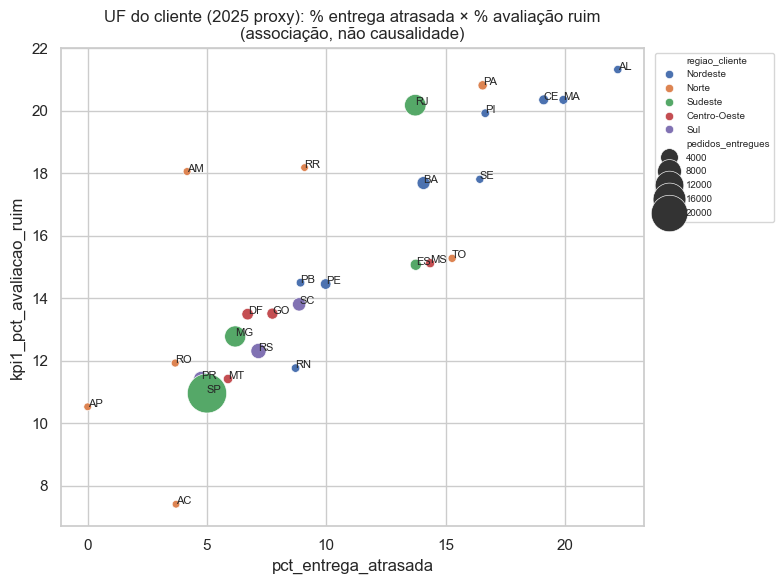

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=uf25, x="pct_entrega_atrasada", y="kpi1_pct_avaliacao_ruim", size="pedidos_entregues",
                hue="regiao_cliente", sizes=(30, 800), ax=ax)
for _, r in uf25.iterrows():
    ax.annotate(r["customer_state"], (r["pct_entrega_atrasada"], r["kpi1_pct_avaliacao_ruim"]), fontsize=8)
ax.set_title("UF do cliente (2025 proxy): % entrega atrasada × % avaliação ruim\n(associação, não causalidade)")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout(); fig.savefig(U.FIG_DIR / "04_uf_atraso_vs_ruim.png", dpi=120)

## 3. Por categoria de produto
`categoria_en` usa a tradução oficial; quando não há tradução, mantém o nome original; produtos sem categoria aparecem como `sem_categoria`.

In [7]:
chave_c = ["ano_original", "periodo_comparativo", "categoria_en"]
cat_ped = U.kpi_pedidos(pc, chave_c)
cat_it = U.kpi_frete(itens, chave_c)
cat = cat_ped.merge(cat_it, on=chave_c, how="outer", validate="one_to_one")
cat = U.flag_amostra(cat, "pedidos_com_avaliacao")
cat["granularidade"] = "periodo_categoria (pedido contado em cada categoria que contém)"
print("Categorias:", cat["categoria_en"].nunique(), "| grupos com amostra pequena:", int(cat["amostra_pequena"].sum()))

cat25 = cat[(cat["ano_original"] == 2018)].copy()
cat25["excesso_pedidos_ruins"] = cat25["pedidos_avaliacao_ruim"] - cat25["pedidos_com_avaliacao"] * taxa_geral
print("Maior % avaliação ruim (somente categorias com >= 30 avaliações):")
display(cat25[~cat25["amostra_pequena"]].sort_values("kpi1_pct_avaliacao_ruim", ascending=False)
        .set_index("categoria_en")[SHOW].head(12).round(2))
print("Maior excesso de pedidos ruins (volume x taxa):")
cat25.sort_values("excesso_pedidos_ruins", ascending=False).set_index("categoria_en")[
    SHOW + ["excesso_pedidos_ruins"]].head(12).round(2)

Categorias: 74 | grupos com amostra pequena: 46
Maior % avaliação ruim (somente categorias com >= 30 avaliações):


,pedidos_entregues,pedidos_com_avaliacao,kpi1_pct_avaliacao_ruim,kpi2_pct_frete_sobre_produto,kpi3_pct_postagem_no_prazo,pct_entrega_atrasada,amostra_pequena
categoria_en,,,,,,,
office_furniture,636,631,22.82,26.55,73.27,7.55,False
fixed_telephony,85,85,22.35,7.26,85.88,8.24,False
fashion_underwear_beach,37,36,22.22,26.32,64.86,18.92,False
audio,187,186,22.04,10.01,89.84,12.30,False
sem_categoria,605,601,18.64,16.43,88.10,8.76,False
furniture_living_room,211,211,18.01,27.19,88.63,7.58,False
home_construction,373,372,17.20,17.40,79.62,6.43,False
home_confort,146,146,17.12,15.80,94.52,10.27,False
construction_tools_safety,125,124,16.94,9.71,87.20,2.40,False


Maior excesso de pedidos ruins (volume x taxa):


,pedidos_entregues,pedidos_com_avaliacao,kpi1_pct_avaliacao_ruim,kpi2_pct_frete_sobre_produto,kpi3_pct_postagem_no_prazo,pct_entrega_atrasada,amostra_pequena,excesso_pedidos_ruins
categoria_en,,,,,,,,
bed_bath_table,4844,4799,16.55,20.91,93.52,8.18,False,152.28
computers_accessories,3972,3956,15.87,17.68,89.25,7.66,False,99.01
office_furniture,636,631,22.82,26.55,73.27,7.55,False,59.62
furniture_decor,3147,3130,15.21,23.16,90.31,7.50,False,57.46
watches_gifts,3418,3392,14.92,9.00,91.72,8.52,False,52.42
telephony,2117,2103,15.50,20.94,91.21,8.60,False,44.79
baby,1627,1616,15.66,16.41,90.72,8.48,False,36.91
sem_categoria,605,601,18.64,16.43,88.10,8.76,False,31.63
audio,187,186,22.04,10.01,89.84,12.30,False,16.13


In [8]:
print("Maior % frete sobre produto (categorias com >= 30 avaliações):")
cat25[~cat25["amostra_pequena"]].sort_values("kpi2_pct_frete_sobre_produto", ascending=False) \
    .set_index("categoria_en")[["itens", "soma_frete", "soma_preco_produtos", "kpi2_pct_frete_sobre_produto",
                                 "kpi1_pct_avaliacao_ruim"]].head(10).round(2)

Maior % frete sobre produto (categorias com >= 30 avaliações):


,itens,soma_frete,soma_preco_produtos,kpi2_pct_frete_sobre_produto,kpi1_pct_avaliacao_ruim
categoria_en,,,,,
christmas_supplies,89,2117.25,5910.90,35.82,13.16
signaling_and_security,153,5346.85,17066.24,31.33,9.52
food_drink,145,2362.74,7655.94,30.86,4.27
electronics,1837,30730.74,99735.60,30.81,13.27
furniture_living_room,239,9098.13,33467.26,27.19,18.01
books_technical,219,3452.21,12940.01,26.68,9.91
office_furniture,870,37326.01,140578.35,26.55,22.82
fashion_underwear_beach,42,634.13,2409.10,26.32,22.22
drinks,279,4286.02,16883.19,25.39,11.06


## 4. Exportação

In [9]:
U.export_csv(reg, "kpi_regiao")
U.export_csv(uf, "kpi_uf")
U.export_csv(cat, "kpi_categoria")
print("Exportados: kpi_regiao.csv, kpi_uf.csv, kpi_categoria.csv")

Exportados: kpi_regiao.csv, kpi_uf.csv, kpi_categoria.csv
